# RealSense D435i RGB global detection


In [29]:
"""Rule-based global RGB detection for mechanical parts on a white worktable.

Test image:
    realsense_color_20260605_181847.png

The detector intentionally uses only RGB data. It is organized so the masks and
geometry thresholds can later be reused in an RGB-D eye-in-hand workflow.
"""

'Rule-based global RGB detection for mechanical parts on a white worktable.\n\nTest image:\n    realsense_color_20260605_181847.png\n\nThe detector intentionally uses only RGB data. It is organized so the masks and\ngeometry thresholds can later be reused in an RGB-D eye-in-hand workflow.\n'

## Part 1: imports and parameters

In [30]:
from __future__ import annotations

import csv
import json
import math
from pathlib import Path
from typing import Any

import cv2
import matplotlib.pyplot as plt
import numpy as np


def find_project_root() -> Path:
    """Find the project directory without relying on a machine-specific path."""
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / "global_rgb_part_detection.ipynb").is_file():
            return candidate
    return current


ROOT = find_project_root()
IMAGE_PATH = Path("realsense_pic") / "realsense_color_20260618_135941.png"
OUTPUT_DIR = ROOT / "output" / "global_detection"

# Manual mask is preferred for the current fixed global camera view.
USE_MANUAL_WORK_AREA = True
MANUAL_WORK_AREA_POLYGON = np.array(
    [
        [104, 0],
        [568, 0],
        [588, 330],
        [455, 480],
        [120, 480],
    ],
    dtype=np.int32,
)
WORK_MASK_ERODE_PX = 3

# Red segmentation: OpenCV hue range is [0, 179].
RED_HSV_LOW_1 = (0, 90, 55)
RED_HSV_HIGH_1 = (12, 255, 255)
RED_HSV_LOW_2 = (168, 90, 55)
RED_HSV_HIGH_2 = (179, 255, 255)
RED_OPEN_KERNEL = 3
RED_CLOSE_KERNEL = 7
# One close pass fills small red gaps without joining the black-topped screw
# to a nearby gear. Two passes bridge the current screw and Gear_large masks.
RED_CLOSE_ITERATIONS = 1
RED_MIN_AREA_PX = 180
RED_MAX_AREA_PX = 30000
# Gear contours are much larger than the screw. This rejects thin red base
# reflections/fragments without changing the three real gear thresholds.
RED_GEAR_MIN_AREA_PX = 2500
RED_SCREW_MAX_AREA_PX = 1500
RED_SCREW_MAX_DIM_PX = 55
RED_HOLE_MIN_AREA_PX = 90
RED_GEAR_SMALL_MAX_EQ_DIAMETER_PX = 125

# Black shaft segmentation and filtering.
BLACK_MAX_VALUE = 82
BLACK_MIN_AREA_PX = 550
BLACK_MAX_AREA_PX = 4200
BLACK_MIN_RECTANGULARITY = 0.68
BLACK_MAX_LONG_SIDE_PX = 90
BLACK_MIN_SHORT_SIDE_PX = 18
BLACK_MAX_CIRCULARITY_FOR_ROUND_BLOB = 0.86
EXPECTED_SHAFT_COUNT = 2

# True black insert-hole filtering inside the detected base contour.
# This threshold is intentionally separate from BLACK_MAX_VALUE. Base holes can
# look brighter under the silver-base illumination, while shaft segmentation
# should remain strict.
BASE_INSERT_HOLE_MAX_VALUE = 100
BASE_INSERT_HOLE_OPEN_KERNEL = 3
BASE_INSERT_HOLE_CLOSE_KERNEL = 3
BASE_INSERT_HOLE_MIN_AREA = 80
BASE_INSERT_HOLE_MAX_AREA = 2000
BASE_INSERT_HOLE_MIN_RADIUS = 5.0
BASE_INSERT_HOLE_MAX_RADIUS = 30.0
BASE_INSERT_HOLE_MIN_CIRCULARITY = 0.50
BASE_INSERT_HOLE_MIN_ASPECT_RATIO = 0.40
BASE_INSERT_HOLE_MIN_BOUNDARY_DISTANCE = 3.0
BASE_INSERT_HOLE_EXPECTED_COUNT = 3

# Perspective fallback used only when the strict contour rules find fewer
# than three holes. It accepts a moderately elongated dark core, then chooses
# the candidate farthest from already accepted holes.
BASE_INSERT_HOLE_RELAXED_MIN_AREA = 100
BASE_INSERT_HOLE_RELAXED_MIN_CIRCULARITY = 0.42
BASE_INSERT_HOLE_RELAXED_MIN_ASPECT_RATIO = 0.40
BASE_INSERT_HOLE_RELAXED_MIN_DISTANCE_PX = 35.0

# Silver base segmentation.
SILVER_MAX_SATURATION = 50
SILVER_MIN_VALUE = 70
SILVER_MAX_VALUE = 175
SILVER_MAX_L = 168
SILVER_LAB_A_TOLERANCE = 30
SILVER_LAB_B_TOLERANCE = 38
BASE_MIN_AREA_PX = 5000
BASE_MAX_AREA_PX = 60000
BASE_HOLE_MIN_RADIUS_PX = 12
BASE_HOLE_MAX_RADIUS_PX = 31
BASE_HOLE_HOUGH_PARAM2 = 18

# General filtering.
IMAGE_BORDER_MARGIN_PX = 5
MASK_EXCLUSION_DILATE_PX = 7

# Output files.
ANNOTATED_PATH = OUTPUT_DIR / "global_detection_result_black_holes.png"
DEBUG_PATH = OUTPUT_DIR / "global_detection_debug_black_holes.png"
CSV_PATH = OUTPUT_DIR / "global_detection_results.csv"
JSON_PATH = OUTPUT_DIR / "global_detection_results.json"

## Part 2: image loading and optional work-area mask

In [31]:
def load_image(path: str | Path) -> np.ndarray:
    """Load a BGR image from common project-relative locations."""
    requested = Path(path)
    candidates = [
        requested,
        ROOT / requested,
        ROOT / "realsense_pic" / requested.name,
        ROOT / "pic" / requested.name,
    ]
    for candidate in candidates:
        if not candidate.is_file():
            continue
        image = cv2.imread(str(candidate))
        if image is not None:
            print(f"Loaded image: {candidate}")
            return image
    raise FileNotFoundError(
        f"Cannot read {path}. Checked: " + ", ".join(str(p) for p in candidates)
    )


def _auto_detect_white_table(image: np.ndarray) -> np.ndarray:
    """Fallback work-area mask based on the largest bright, low-saturation area."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    white = cv2.inRange(hsv, (0, 0, 145), (179, 90, 255))
    close_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (31, 31))
    white = cv2.morphologyEx(white, cv2.MORPH_CLOSE, close_kernel, iterations=2)

    contours, _ = cv2.findContours(white, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(image.shape[:2], dtype=np.uint8)
    if not contours:
        print("Warning: automatic table detection failed; using the full image.")
        mask[:] = 255
        return mask

    table_contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(table_contour)
    cv2.drawContours(mask, [hull], -1, 255, thickness=-1)
    return mask


def create_work_area_mask(image: np.ndarray) -> np.ndarray:
    """Create the preferred manual polygon mask or an automatic white-table mask."""
    height, width = image.shape[:2]
    mask = np.zeros((height, width), dtype=np.uint8)

    if USE_MANUAL_WORK_AREA and MANUAL_WORK_AREA_POLYGON is not None:
        polygon = MANUAL_WORK_AREA_POLYGON.copy()
        polygon[:, 0] = np.clip(polygon[:, 0], 0, width - 1)
        polygon[:, 1] = np.clip(polygon[:, 1], 0, height - 1)
        cv2.fillPoly(mask, [polygon], 255)
    else:
        mask = _auto_detect_white_table(image)

    if WORK_MASK_ERODE_PX > 0:
        size = 2 * WORK_MASK_ERODE_PX + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
        mask = cv2.erode(mask, kernel, iterations=1)
    return mask

## Part 3: color segmentation utilities

In [32]:
def _odd_kernel(size: int) -> np.ndarray:
    size = max(1, int(size))
    if size % 2 == 0:
        size += 1
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))


def _remove_small_components(mask: np.ndarray, min_area: int) -> np.ndarray:
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean = np.zeros_like(mask)
    for label in range(1, count):
        if stats[label, cv2.CC_STAT_AREA] >= min_area:
            clean[labels == label] = 255
    return clean


def segment_red_objects(image: np.ndarray, work_mask: np.ndarray) -> np.ndarray:
    """Segment red objects using both ends of the HSV hue interval."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    red_1 = cv2.inRange(hsv, RED_HSV_LOW_1, RED_HSV_HIGH_1)
    red_2 = cv2.inRange(hsv, RED_HSV_LOW_2, RED_HSV_HIGH_2)
    red = cv2.bitwise_or(red_1, red_2)
    red = cv2.bitwise_and(red, work_mask)
    red = cv2.morphologyEx(red, cv2.MORPH_OPEN, _odd_kernel(RED_OPEN_KERNEL))
    red = cv2.morphologyEx(
        red,
        cv2.MORPH_CLOSE,
        _odd_kernel(RED_CLOSE_KERNEL),
        iterations=RED_CLOSE_ITERATIONS,
    )
    return _remove_small_components(red, RED_MIN_AREA_PX)


def segment_black_objects(image: np.ndarray, work_mask: np.ndarray) -> np.ndarray:
    """Segment dark objects; geometric filtering later rejects circular base holes."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    black = cv2.inRange(hsv, (0, 0, 0), (179, 255, BLACK_MAX_VALUE))
    black = cv2.bitwise_and(black, work_mask)
    black = cv2.morphologyEx(black, cv2.MORPH_OPEN, _odd_kernel(3))
    black = cv2.morphologyEx(black, cv2.MORPH_CLOSE, _odd_kernel(5))
    return _remove_small_components(black, 80)


def segment_silver_base(
    image: np.ndarray,
    work_mask: np.ndarray,
    red_mask: np.ndarray,
    black_mask: np.ndarray,
) -> np.ndarray:
    """Segment neutral gray/silver pixels while excluding red and black regions."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    _, saturation, value = cv2.split(hsv)
    lab_l, lab_a, lab_b = cv2.split(lab)
    neutral_lab = (
        (np.abs(lab_a.astype(np.int16) - 128) <= SILVER_LAB_A_TOLERANCE)
        & (np.abs(lab_b.astype(np.int16) - 128) <= SILVER_LAB_B_TOLERANCE)
    )
    gray_hsv = (
        (saturation <= SILVER_MAX_SATURATION)
        & (value >= SILVER_MIN_VALUE)
        & (value <= SILVER_MAX_VALUE)
        & (lab_l <= SILVER_MAX_L)
    )
    silver = np.uint8(neutral_lab & gray_hsv) * 255
    silver = cv2.bitwise_and(silver, work_mask)

    exclusion = cv2.bitwise_or(red_mask, black_mask)
    exclusion = cv2.dilate(exclusion, _odd_kernel(MASK_EXCLUSION_DILATE_PX))
    silver[exclusion > 0] = 0

    silver = cv2.morphologyEx(silver, cv2.MORPH_OPEN, _odd_kernel(3))
    silver = cv2.morphologyEx(
        silver, cv2.MORPH_CLOSE, _odd_kernel(11), iterations=1
    )
    return _remove_small_components(silver, 250)


def _contour_touches_image_border(
    contour: np.ndarray, image_shape: tuple[int, ...]
) -> bool:
    x, y, width, height = cv2.boundingRect(contour)
    image_height, image_width = image_shape[:2]
    return (
        x <= IMAGE_BORDER_MARGIN_PX
        or y <= IMAGE_BORDER_MARGIN_PX
        or x + width >= image_width - IMAGE_BORDER_MARGIN_PX
        or y + height >= image_height - IMAGE_BORDER_MARGIN_PX
    )


def _contour_center(contour: np.ndarray) -> tuple[float, float]:
    moments = cv2.moments(contour)
    if abs(moments["m00"]) > 1e-8:
        return (
            float(moments["m10"] / moments["m00"]),
            float(moments["m01"] / moments["m00"]),
        )
    x, y, width, height = cv2.boundingRect(contour)
    return x + width / 2.0, y + height / 2.0


def _estimate_hole_center(contour: np.ndarray) -> tuple[float, float]:
    """Estimate a hole center from its fitted ellipse or enclosing circle."""
    if len(contour) >= 5:
        try:
            (center_u, center_v), _, _ = cv2.fitEllipse(contour)
            if math.isfinite(center_u) and math.isfinite(center_v):
                return float(center_u), float(center_v)
        except cv2.error:
            pass
    try:
        (center_u, center_v), _ = cv2.minEnclosingCircle(contour)
        if math.isfinite(center_u) and math.isfinite(center_v):
            return float(center_u), float(center_v)
    except cv2.error:
        pass
    return _contour_center(contour)


def compute_rotated_rect_features(contour: np.ndarray) -> dict[str, Any]:
    """Return minAreaRect geometry with long-side yaw normalized to [-90, 90)."""
    rect = cv2.minAreaRect(contour)
    (center_u, center_v), (raw_width, raw_height), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float32)

    if raw_width >= raw_height:
        long_side = float(raw_width)
        short_side = float(raw_height)
        yaw_deg = float(raw_angle)
    else:
        long_side = float(raw_height)
        short_side = float(raw_width)
        yaw_deg = float(raw_angle + 90.0)
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0

    edge_midpoints = []
    edge_lengths = []
    for index in range(4):
        point_a = box[index]
        point_b = box[(index + 1) % 4]
        edge_midpoints.append(((point_a + point_b) / 2.0).tolist())
        edge_lengths.append(float(np.linalg.norm(point_b - point_a)))

    angle_rad = math.radians(yaw_deg)
    direction = np.array([math.cos(angle_rad), math.sin(angle_rad)])
    center = np.array([center_u, center_v], dtype=np.float64)
    grasp_offset = 0.22 * long_side
    grasp_candidates = [
        center.tolist(),
        (center + grasp_offset * direction).tolist(),
        (center - grasp_offset * direction).tolist(),
    ]

    return {
        "center": [float(center_u), float(center_v)],
        "raw_size": [float(raw_width), float(raw_height)],
        "long_side_px": long_side,
        "short_side_px": short_side,
        "yaw_deg": yaw_deg,
        "box_points": box.tolist(),
        "edge_midpoints_2d": edge_midpoints,
        "edge_lengths_px": edge_lengths,
        "grasp_candidates_2d": grasp_candidates,
    }


def _basic_contour_features(contour: np.ndarray) -> dict[str, float | int]:
    area = float(cv2.contourArea(contour))
    perimeter = float(cv2.arcLength(contour, True))
    x, y, width, height = cv2.boundingRect(contour)
    hull_area = float(cv2.contourArea(cv2.convexHull(contour)))
    circularity = 4.0 * math.pi * area / (perimeter * perimeter) if perimeter else 0.0
    extent = area / float(width * height) if width and height else 0.0
    solidity = area / hull_area if hull_area else 0.0
    equivalent_diameter = math.sqrt(4.0 * area / math.pi) if area else 0.0
    approx = cv2.approxPolyDP(contour, 0.01 * perimeter, True)
    return {
        "area": area,
        "perimeter": perimeter,
        "bbox_x": int(x),
        "bbox_y": int(y),
        "bbox_w": int(width),
        "bbox_h": int(height),
        "circularity": float(circularity),
        "extent": float(extent),
        "solidity": float(solidity),
        "equivalent_diameter": float(equivalent_diameter),
        "contour_complexity": int(len(approx)),
    }


def _find_holes_inside_contour(
    contour: np.ndarray, object_mask: np.ndarray
) -> list[np.ndarray]:
    filled = np.zeros_like(object_mask)
    cv2.drawContours(filled, [contour], -1, 255, thickness=-1)
    holes = cv2.bitwise_and(filled, cv2.bitwise_not(object_mask))
    hole_contours, _ = cv2.findContours(
        holes, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    return [
        hole
        for hole in hole_contours
        if cv2.contourArea(hole) >= RED_HOLE_MIN_AREA_PX
    ]


def _find_inner_square_center(
    contour: np.ndarray, red_mask: np.ndarray
) -> list[float] | None:
    object_center = np.array(_contour_center(contour))
    candidates = []
    for hole in _find_holes_inside_contour(contour, red_mask):
        perimeter = cv2.arcLength(hole, True)
        approx = cv2.approxPolyDP(hole, 0.04 * perimeter, True)
        area = cv2.contourArea(hole)
        if 4 <= len(approx) <= 6 and 100 <= area <= 3500:
            center = np.array(_contour_center(hole))
            candidates.append((float(np.linalg.norm(center - object_center)), center))
    if not candidates:
        return None
    _, center = min(candidates, key=lambda item: item[0])
    return [float(center[0]), float(center[1])]


def _new_result(
    class_name: str,
    contour: np.ndarray,
    confidence: str,
    rule_note: str,
) -> dict[str, Any]:
    features = _basic_contour_features(contour)
    rotated = compute_rotated_rect_features(contour)
    center_u, center_v = _contour_center(contour)
    return {
        "class_name": class_name,
        "center_u": round(center_u, 2),
        "center_v": round(center_v, 2),
        "bbox_x": features["bbox_x"],
        "bbox_y": features["bbox_y"],
        "bbox_w": features["bbox_w"],
        "bbox_h": features["bbox_h"],
        "area_px": round(float(features["area"]), 1),
        "yaw_deg": round(float(rotated["yaw_deg"]), 2),
        "confidence": confidence,
        "rule_note": rule_note,
        "type_certain": bool(confidence == "high"),
        "classification_status": ("certain" if confidence == "high" else "uncertain"),
        "classification_reason": rule_note,
        "classification_set_complete": None,
        "gear_outer_radius_px": None,
        "gear_inner_square_center": None,
        "grasp_hint_2d": None,
        "rect_width_px": None,
        "rect_height_px": None,
        "long_side_px": None,
        "short_side_px": None,
        "edge_midpoints_2d": None,
        "grasp_candidates_2d": None,
        "base_contour_area": None,
        "base_rotated_rect": None,
        "base_hole_candidates_2d": None,
        "_contour": contour,
        "_rotated_rect": rotated,
        "_features": features,
    }

## Part 4: red object detection and classification

In [33]:
def classify_red_part(
    contour: np.ndarray, image: np.ndarray, red_mask: np.ndarray | None = None
) -> tuple[str, str, str]:
    """Classify one red contour using size, holes, and gear-like complexity."""
    del image  # Reserved for future texture-based rules.
    features = _basic_contour_features(contour)
    max_dim = max(features["bbox_w"], features["bbox_h"])
    holes = _find_holes_inside_contour(contour, red_mask) if red_mask is not None else []
    hole_count = len(holes)

    if (
        features["area"] <= RED_SCREW_MAX_AREA_PX
        and max_dim <= RED_SCREW_MAX_DIM_PX
    ):
        return "Screw", "high", "small red component; compact non-gear geometry"

    if hole_count >= 3:
        return (
            "Gear_large",
            "high",
            f"large gear-like contour with {hole_count} significant internal holes",
        )

    if (
        features["equivalent_diameter"] <= RED_GEAR_SMALL_MAX_EQ_DIAMETER_PX
        and hole_count >= 1
    ):
        return (
            "Gear_small",
            "high",
            "medium red gear-like contour with a central hole",
        )

    if features["area"] > 6000 and hole_count <= 2:
        return (
            "Gear_compound",
            "medium",
            "large gear-like contour; compound structure inferred by size and few through-holes",
        )

    return "Gear_small", "medium", "red gear candidate classified mainly by size"


def detect_red_parts(image: np.ndarray, red_mask: np.ndarray) -> list[dict[str, Any]]:
    """Detect red components, then refine the three gear labels jointly."""
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if not RED_MIN_AREA_PX <= area <= RED_MAX_AREA_PX:
            continue
        class_name, confidence, note = classify_red_part(contour, image, red_mask)
        if class_name != "Screw" and area < RED_GEAR_MIN_AREA_PX:
            continue
        result = _new_result(class_name, contour, confidence, note)
        if class_name == "Screw":
            # A painted black top removes red pixels asymmetrically. The
            # minAreaRect center follows the outer screw silhouette better
            # than the red-area centroid.
            screw_center = cv2.minAreaRect(contour)[0]
            result["center_u"] = round(float(screw_center[0]), 2)
            result["center_v"] = round(float(screw_center[1]), 2)
            result["rule_note"] += "; center from red outer-shape minAreaRect"
        holes = _find_holes_inside_contour(contour, red_mask)
        result["_hole_count"] = len(holes)
        result["_hole_areas"] = [float(cv2.contourArea(hole)) for hole in holes]
        candidates.append(result)

    # Refine labels using relative geometry when exactly three gear candidates exist.
    gear_candidates = [item for item in candidates if item["class_name"] != "Screw"]
    if len(gear_candidates) == 3:
        large = max(gear_candidates, key=lambda item: (item["_hole_count"], item["area_px"]))
        remaining = [item for item in gear_candidates if item is not large]
        compound = max(remaining, key=lambda item: item["area_px"])
        small = min(remaining, key=lambda item: item["area_px"])

        large["class_name"] = "Gear_large"
        large["confidence"] = "high" if large["_hole_count"] >= 3 else "medium"
        large["rule_note"] = (
            f"largest multi-hole gear; {large['_hole_count']} significant holes"
        )
        small["class_name"] = "Gear_small"
        small["confidence"] = "high" if small["_hole_count"] >= 1 else "medium"
        small["rule_note"] = "smallest gear candidate; central-hole evidence included"
        compound["class_name"] = "Gear_compound"
        compound["confidence"] = "medium"
        compound["rule_note"] = (
            "large remaining gear with few through-holes; size/structure fallback, "
            "not y-position only"
        )
        for gear in gear_candidates:
            gear["type_certain"] = True
            gear["classification_status"] = "certain"
            gear["classification_set_complete"] = True
            gear["classification_reason"] = (
                "all three gear candidates detected; label refined jointly by "
                "hole structure and relative size"
            )
    else:
        for gear in gear_candidates:
            gear["type_certain"] = False
            gear["classification_status"] = "uncertain"
            gear["classification_set_complete"] = False
            gear["classification_reason"] = (
                f"only {len(gear_candidates)} of 3 expected gear candidates detected; "
                "class_name is an absolute-geometry best guess"
            )
            if gear["confidence"] == "high":
                gear["confidence"] = "medium"

    for result in candidates:
        if result["class_name"].startswith("Gear"):
            contour = result["_contour"]
            (_, _), radius = cv2.minEnclosingCircle(contour)
            square_center = _find_inner_square_center(contour, red_mask)
            result["gear_outer_radius_px"] = round(float(radius), 2)
            result["gear_inner_square_center"] = square_center
            result["grasp_hint_2d"] = [
                round(float(result["center_u"]), 2),
                round(float(result["center_v"]), 2),
            ]

    return candidates

## Part 5: black shaft detection and classification

In [34]:
def classify_shaft(contour: np.ndarray) -> tuple[str, str, str]:
    """Provide a provisional shaft label; relative size is refined jointly."""
    rotated = compute_rotated_rect_features(contour)
    rect_area = rotated["long_side_px"] * rotated["short_side_px"]
    if rect_area >= 1450:
        return "Shaft_large", "high", "dark rectangular component with larger rotated area"
    return "Shaft_small", "medium", "dark rectangular component with smaller rotated area"


def detect_black_shafts(
    image: np.ndarray, black_mask: np.ndarray
) -> list[dict[str, Any]]:
    """Detect rectangular black shafts and reject round dark holes in the base."""
    contours, _ = cv2.findContours(
        black_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    shaft_candidates = []
    for contour in contours:
        features = _basic_contour_features(contour)
        if not BLACK_MIN_AREA_PX <= features["area"] <= BLACK_MAX_AREA_PX:
            continue
        if _contour_touches_image_border(contour, image.shape):
            continue

        rotated = compute_rotated_rect_features(contour)
        rect_area = rotated["long_side_px"] * rotated["short_side_px"]
        rectangularity = features["area"] / rect_area if rect_area > 0 else 0.0
        looks_round = (
            features["circularity"] >= BLACK_MAX_CIRCULARITY_FOR_ROUND_BLOB
            and features["contour_complexity"] > 6
        )
        if looks_round:
            continue
        if rectangularity < BLACK_MIN_RECTANGULARITY:
            continue
        if rotated["long_side_px"] > BLACK_MAX_LONG_SIDE_PX:
            continue
        if rotated["short_side_px"] < BLACK_MIN_SHORT_SIDE_PX:
            continue

        class_name, confidence, note = classify_shaft(contour)
        result = _new_result(class_name, contour, confidence, note)
        result["_rect_area"] = rect_area
        result["_rectangularity"] = rectangularity
        result["rect_width_px"] = round(float(rotated["raw_size"][0]), 2)
        result["rect_height_px"] = round(float(rotated["raw_size"][1]), 2)
        result["long_side_px"] = round(float(rotated["long_side_px"]), 2)
        result["short_side_px"] = round(float(rotated["short_side_px"]), 2)
        result["edge_midpoints_2d"] = rotated["edge_midpoints_2d"]
        result["grasp_candidates_2d"] = rotated["grasp_candidates_2d"]
        shaft_candidates.append(result)

    shaft_candidates.sort(key=lambda item: item["_rect_area"], reverse=True)
    if len(shaft_candidates) > EXPECTED_SHAFT_COUNT:
        shaft_candidates = shaft_candidates[:EXPECTED_SHAFT_COUNT]

    shaft_size_margin_ratio = None
    shaft_set_complete = len(shaft_candidates) == EXPECTED_SHAFT_COUNT
    if shaft_set_complete:
        shaft_size_margin_ratio = float(
            (shaft_candidates[0]["_rect_area"] - shaft_candidates[1]["_rect_area"])
            / max(shaft_candidates[0]["_rect_area"], 1e-6)
        )

    if len(shaft_candidates) >= 1:
        shaft_candidates[0]["class_name"] = "Shaft_large"
        shaft_candidates[0]["rule_note"] = (
            "largest of two valid dark rectangular components"
            if shaft_set_complete else
            "only one shaft candidate detected; large label is provisional"
        )
    if len(shaft_candidates) >= 2:
        shaft_candidates[1]["class_name"] = "Shaft_small"
        shaft_candidates[1]["rule_note"] = (
            "smaller of two valid dark rectangular components"
        )

    shaft_types_separated = bool(
        shaft_set_complete and shaft_size_margin_ratio is not None
        and shaft_size_margin_ratio >= 0.08
    )
    for shaft in shaft_candidates:
        shaft["shaft_size_margin_ratio"] = (
            round(shaft_size_margin_ratio, 4)
            if shaft_size_margin_ratio is not None else None
        )
        shaft["classification_set_complete"] = shaft_set_complete
        shaft["type_certain"] = shaft_types_separated
        shaft["classification_status"] = (
            "certain" if shaft_types_separated else "uncertain"
        )
        shaft["classification_reason"] = (
            "two shaft candidates detected with sufficient rotated-area separation"
            if shaft_types_separated else
            "shaft set incomplete or large/small rotated-area separation below 8%"
        )
        shaft["confidence"] = "high" if shaft_types_separated else "low"
    return shaft_candidates

## Part 6: silver base and black insert-hole detection

Base 外轮廓继续使用银色 mask；三个插孔严格从 `black_mask AND filled(base_contour)` 中检测。

In [35]:
def detect_base_insert_holes_from_black_mask(
    image: np.ndarray,
    base_contour: np.ndarray,
    black_mask: np.ndarray,
) -> tuple[list[dict[str, Any]], np.ndarray, np.ndarray, np.ndarray]:
    """Detect three insert holes using cleaned masks and robust ellipse centers."""
    base_roi_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    cv2.drawContours(base_roi_mask, [base_contour], -1, 255, thickness=-1)

    # Keep the hole threshold local to the base so shaft segmentation is unchanged.
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    base_dark_mask = cv2.inRange(
        hsv, (0, 0, 0), (179, 255, BASE_INSERT_HOLE_MAX_VALUE)
    )
    hole_search_mask = cv2.bitwise_and(base_dark_mask, base_roi_mask)
    hole_search_mask = cv2.bitwise_or(
        hole_search_mask, cv2.bitwise_and(black_mask, base_roi_mask)
    )
    hole_search_mask = cv2.morphologyEx(
        hole_search_mask,
        cv2.MORPH_OPEN,
        _odd_kernel(BASE_INSERT_HOLE_OPEN_KERNEL),
    )
    hole_search_mask = cv2.morphologyEx(
        hole_search_mask,
        cv2.MORPH_CLOSE,
        _odd_kernel(BASE_INSERT_HOLE_CLOSE_KERNEL),
    )

    contours, _ = cv2.findContours(
        hole_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    strict_candidates = []
    relaxed_candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        perimeter = float(cv2.arcLength(contour, True))
        circularity = (
            4.0 * math.pi * area / (perimeter * perimeter)
            if perimeter else 0.0
        )
        x, y, width, height = cv2.boundingRect(contour)
        aspect_ratio = (
            min(width, height) / max(width, height)
            if max(width, height) else 0.0
        )
        (_, _), radius = cv2.minEnclosingCircle(contour)
        center_u, center_v = _estimate_hole_center(contour)

        ellipse_major = 2.0 * float(radius)
        ellipse_minor = 2.0 * float(radius)
        if len(contour) >= 5:
            try:
                _, (ellipse_width, ellipse_height), _ = cv2.fitEllipse(contour)
                ellipse_major = max(float(ellipse_width), float(ellipse_height))
                ellipse_minor = min(float(ellipse_width), float(ellipse_height))
            except cv2.error:
                pass
        ellipse_aspect_ratio = (
            ellipse_minor / ellipse_major if ellipse_major > 1e-6 else 0.0
        )
        boundary_distance = cv2.pointPolygonTest(
            base_contour, (float(center_u), float(center_v)), True
        )

        if not (
            BASE_INSERT_HOLE_RELAXED_MIN_AREA
            <= area
            <= BASE_INSERT_HOLE_MAX_AREA
            and BASE_INSERT_HOLE_MIN_RADIUS
            <= radius
            <= BASE_INSERT_HOLE_MAX_RADIUS
            and boundary_distance >= BASE_INSERT_HOLE_MIN_BOUNDARY_DISTANCE
        ):
            continue

        circularity_score = min(
            max(
                (circularity - BASE_INSERT_HOLE_MIN_CIRCULARITY)
                / max(1.0 - BASE_INSERT_HOLE_MIN_CIRCULARITY, 1e-6),
                0.0,
            ),
            1.0,
        )
        ellipse_score = min(
            max(
                (ellipse_aspect_ratio - BASE_INSERT_HOLE_MIN_ASPECT_RATIO)
                / max(1.0 - BASE_INSERT_HOLE_MIN_ASPECT_RATIO, 1e-6),
                0.0,
            ),
            1.0,
        )
        radius_midpoint = 0.5 * (
            BASE_INSERT_HOLE_MIN_RADIUS + BASE_INSERT_HOLE_MAX_RADIUS
        )
        radius_half_range = 0.5 * (
            BASE_INSERT_HOLE_MAX_RADIUS - BASE_INSERT_HOLE_MIN_RADIUS
        )
        radius_score = max(
            0.0, 1.0 - abs(radius - radius_midpoint) / radius_half_range
        )
        boundary_score = min(max(boundary_distance / 25.0, 0.0), 1.0)
        area_score = min(area / BASE_INSERT_HOLE_MAX_AREA, 1.0)
        score = (
            0.35 * circularity_score
            + 0.30 * ellipse_score
            + 0.20 * boundary_score
            + 0.10 * radius_score
            + 0.05 * area_score
        )
        candidate = {
            "contour": contour,
            "center_u": float(center_u),
            "center_v": float(center_v),
            "radius_px": float(radius),
            "area_px": area,
            "circularity": float(circularity),
            "aspect_ratio": float(aspect_ratio),
            "ellipse_major_px": float(ellipse_major),
            "ellipse_minor_px": float(ellipse_minor),
            "ellipse_aspect_ratio": float(ellipse_aspect_ratio),
            "boundary_distance_px": float(boundary_distance),
            "score": float(score),
            "selection_rule": "strict",
        }
        if (
            area >= BASE_INSERT_HOLE_MIN_AREA
            and circularity >= BASE_INSERT_HOLE_MIN_CIRCULARITY
            and aspect_ratio >= BASE_INSERT_HOLE_MIN_ASPECT_RATIO
        ):
            strict_candidates.append(candidate)
        elif (
            circularity >= BASE_INSERT_HOLE_RELAXED_MIN_CIRCULARITY
            and aspect_ratio >= BASE_INSERT_HOLE_RELAXED_MIN_ASPECT_RATIO
        ):
            candidate["selection_rule"] = "perspective_relaxed"
            relaxed_candidates.append(candidate)

    all_candidates = strict_candidates + relaxed_candidates
    strict_candidates.sort(key=lambda item: item["score"], reverse=True)
    selected = strict_candidates[:BASE_INSERT_HOLE_EXPECTED_COUNT]

    # Supplement only missing holes; reject nearby slot/edge fragments.
    while len(selected) < BASE_INSERT_HOLE_EXPECTED_COUNT and relaxed_candidates:
        def separation_from_selected(candidate):
            if not selected:
                return float("inf")
            return min(
                math.hypot(
                    candidate["center_u"] - item["center_u"],
                    candidate["center_v"] - item["center_v"],
                )
                for item in selected
            )

        relaxed_candidates.sort(
            key=lambda item: (separation_from_selected(item), item["score"]),
            reverse=True,
        )
        candidate = relaxed_candidates.pop(0)
        if (
            separation_from_selected(candidate)
            < BASE_INSERT_HOLE_RELAXED_MIN_DISTANCE_PX
        ):
            break
        selected.append(candidate)

    # Semantic slot assignment is allowed only when all three holes exist.
    # The horizontally middle hole is the screw slot. Of the remaining
    # two, ellipse minor diameter is the primary large/small cue; image
    # height (smaller v means higher) is used only as a tie-breaker.
    assigned = []
    assignment_confidence = "failed"
    size_margin_ratio = None
    if len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT:
        horizontal = sorted(selected, key=lambda item: item["center_u"])
        screw_candidate = horizontal[1]
        shaft_candidates = [horizontal[0], horizontal[2]]
        shaft_candidates.sort(
            key=lambda item: (item["ellipse_minor_px"], -item["center_v"]),
            reverse=True,
        )
        large_candidate, small_candidate = shaft_candidates
        size_margin_ratio = float(
            (large_candidate["ellipse_minor_px"] - small_candidate["ellipse_minor_px"])
            / max(large_candidate["ellipse_minor_px"], 1e-6)
        )
        assignment_confidence = (
            "high" if size_margin_ratio >= 0.08 else
            "medium" if size_margin_ratio >= 0.04 else "low"
        )
        assigned = [
            ("hole_large", large_candidate),
            ("hole_small", small_candidate),
            ("hole_screw", screw_candidate),
        ]
    else:
        assignment_confidence = "uncertain"
        assigned = [
            (f"hole_unknown_{index + 1}", candidate)
            for index, candidate in enumerate(
                sorted(selected, key=lambda item: item["center_u"])
            )
        ]

    results = []
    for hole_name, candidate in assigned:
        relaxed = candidate["selection_rule"] != "strict"
        result = _new_result(
            f"base_{hole_name}",
            candidate["contour"],
            "medium" if relaxed or candidate["circularity"] < 0.75 else "high",
            (
                "dark insert-hole contour inside base ROI; perspective-relaxed "
                "shape; center from ellipse/circle fit"
                if relaxed else
                "dark insert-hole contour inside base ROI; center from "
                "ellipse/circle fit"
            ),
        )
        result["center_u"] = round(candidate["center_u"], 2)
        result["center_v"] = round(candidate["center_v"], 2)
        result["yaw_deg"] = None
        result["hole_name"] = hole_name
        result["hole_radius_px"] = round(candidate["radius_px"], 2)
        result["hole_ellipse_major_px"] = round(candidate["ellipse_major_px"], 2)
        result["hole_ellipse_minor_px"] = round(candidate["ellipse_minor_px"], 2)
        result["hole_circularity"] = round(candidate["circularity"], 4)
        result["hole_boundary_distance_px"] = round(
            candidate["boundary_distance_px"], 2
        )
        result["hole_assignment_confidence"] = assignment_confidence
        hole_type_certain = bool(
            len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT
            and assignment_confidence == "high"
        )
        result["type_certain"] = hole_type_certain
        result["classification_status"] = (
            "certain" if hole_type_certain else "uncertain"
        )
        result["classification_set_complete"] = bool(
            len(selected) == BASE_INSERT_HOLE_EXPECTED_COUNT
        )
        result["classification_reason"] = (
            "all three holes detected with sufficient large/small size separation"
            if hole_type_certain else
            f"detected {len(selected)} of 3 holes or semantic size separation is insufficient"
        )
        result["detected_hole_count"] = int(len(selected))
        result["expected_hole_count"] = int(BASE_INSERT_HOLE_EXPECTED_COUNT)
        if assignment_confidence in ("low", "uncertain"):
            result["confidence"] = "low"
        elif assignment_confidence == "medium" and result["confidence"] == "high":
            result["confidence"] = "medium"
        result["hole_size_margin_ratio"] = (
            round(size_margin_ratio, 4) if size_margin_ratio is not None else None
        )
        result["hole_assignment_rule"] = (
            "middle-u hole is screw; remaining holes use ellipse-minor "
            "diameter, with smaller image-v as tie-breaker for large"
        )
        results.append(result)

    if len(results) < BASE_INSERT_HOLE_EXPECTED_COUNT:
        print(
            f"Warning: expected exactly {BASE_INSERT_HOLE_EXPECTED_COUNT} base insert holes; "
            "semantic hole assignment was rejected."
        )

    candidates_mask = np.zeros_like(hole_search_mask)
    candidate_debug = image.copy()
    for candidate in all_candidates:
        center = (
            int(round(candidate["center_u"])),
            int(round(candidate["center_v"])),
        )
        cv2.drawContours(
            candidates_mask, [candidate["contour"]], -1, 255, thickness=1
        )
        cv2.circle(candidates_mask, center, 2, 255, thickness=-1)
        cv2.drawMarker(
            candidate_debug, center, (0, 165, 255),
            cv2.MARKER_TILTED_CROSS, 12, 1, cv2.LINE_AA
        )
    for result in results:
        center = (int(round(result["center_u"])), int(round(result["center_v"])))
        cv2.circle(candidate_debug, center, 3, (255, 255, 0), -1)
        cv2.drawMarker(
            candidate_debug, center, (255, 255, 0),
            cv2.MARKER_CROSS, 14, 2, cv2.LINE_AA
        )
        cv2.putText(
            candidate_debug, result["hole_name"],
            (center[0] + 7, center[1] - 7),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2, cv2.LINE_AA
        )
    return results, hole_search_mask, candidates_mask, candidate_debug


def detect_silver_base(
    image: np.ndarray, base_mask: np.ndarray
) -> list[dict[str, Any]]:
    """Keep the original silver Base contour; holes are detected separately."""
    contours, _ = cv2.findContours(
        base_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = [
        contour
        for contour in contours
        if BASE_MIN_AREA_PX <= cv2.contourArea(contour) <= BASE_MAX_AREA_PX
        and not _contour_touches_image_border(contour, image.shape)
    ]
    if not candidates:
        print("Warning: Base was not detected.")
        return []

    contour = max(candidates, key=cv2.contourArea)
    result = _new_result(
        "Base",
        contour,
        "high",
        "largest neutral-gray object; black insert holes detected separately",
    )
    rotated = result["_rotated_rect"]
    result["base_contour_area"] = round(float(cv2.contourArea(contour)), 1)
    result["base_rotated_rect"] = {
        "center": rotated["center"],
        "size": rotated["raw_size"],
        "yaw_deg": rotated["yaw_deg"],
        "box_points": rotated["box_points"],
    }
    result["base_hole_candidates_2d"] = None
    result["base_insert_holes_2d"] = []
    return [result]


## Part 7: result visualization

孔只画 cyan 中心点和十字，不绘制孔轮廓或银色圆环。

In [36]:
CLASS_COLORS = {
    "Gear_large": (20, 20, 255),
    "Gear_small": (0, 110, 255),
    "Gear_compound": (180, 0, 255),
    "Screw": (0, 220, 255),
    "Shaft_large": (255, 80, 20),
    "Shaft_small": (255, 180, 20),
    "Base": (40, 220, 40),
    "base_hole_large": (0, 255, 255),
    "base_hole_small": (255, 255, 0),
    "base_hole_screw": (0, 200, 255),
    "base_hole_unknown_1": (128, 128, 128),
    "base_hole_unknown_2": (128, 128, 128),
}


def draw_results(image: np.ndarray, results: list[dict[str, Any]]) -> np.ndarray:
    """Draw normal parts normally; draw base holes as center-only cyan markers."""
    annotated = image.copy()
    for result in results:
        class_name = result["class_name"]
        color = CLASS_COLORS.get(class_name, (255, 255, 0))
        center = np.array([result["center_u"], result["center_v"]], dtype=float)
        center_int = tuple(np.round(center).astype(int))

        if class_name.startswith("base_hole_"):
            # Deliberately do not draw the contour, radius, bbox, or silver ring.
            cv2.circle(annotated, center_int, 3, color, -1, cv2.LINE_AA)
            cv2.drawMarker(
                annotated, center_int, color,
                cv2.MARKER_CROSS, 14, 2, cv2.LINE_AA
            )
            label = (
                f"{result['hole_name']}"
                f"{' UNCERTAIN' if not result.get('type_certain', False) else ''} "
                f"({result['center_u']:.0f},{result['center_v']:.0f})"
            )
            text_position = (center_int[0] + 8, center_int[1] - 8)
        else:
            contour = result["_contour"]
            cv2.drawContours(annotated, [contour], -1, color, 2)
            rotated = result["_rotated_rect"]
            box = np.round(np.array(rotated["box_points"])).astype(np.int32)
            cv2.polylines(annotated, [box], True, color, 1, cv2.LINE_AA)
            cv2.circle(annotated, center_int, 5, color, -1)

            yaw_rad = math.radians(result["yaw_deg"])
            line_length = max(24.0, 0.45 * float(rotated["long_side_px"]))
            endpoint = center + line_length * np.array(
                [math.cos(yaw_rad), math.sin(yaw_rad)]
            )
            cv2.line(
                annotated, center_int, tuple(np.round(endpoint).astype(int)),
                color, 2, cv2.LINE_AA
            )
            label = (
                f"{class_name} {result['confidence']}"
                f"{' UNCERTAIN' if not result.get('type_certain', False) else ''} "
                f"({result['center_u']:.0f},{result['center_v']:.0f})"
            )
            text_position = (
                int(result["bbox_x"]),
                max(18, int(result["bbox_y"]) - 7),
            )

        cv2.putText(
            annotated, label, text_position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.48, (0, 0, 0), 3, cv2.LINE_AA
        )
        cv2.putText(
            annotated, label, text_position,
            cv2.FONT_HERSHEY_SIMPLEX, 0.48, color, 1, cv2.LINE_AA
        )
    return annotated


def show_and_save_debug(
    image: np.ndarray,
    work_mask: np.ndarray,
    red_mask: np.ndarray,
    black_mask: np.ndarray,
    base_mask: np.ndarray,
    base_hole_search_mask: np.ndarray,
    base_hole_candidates_mask: np.ndarray,
    hole_candidate_debug: np.ndarray,
    annotated: np.ndarray,
) -> None:
    panels = [
        ("Original", cv2.cvtColor(image, cv2.COLOR_BGR2RGB), None),
        ("Work-area mask", work_mask, "gray"),
        ("Red mask", red_mask, "gray"),
        ("Black mask", black_mask, "gray"),
        ("Silver/base mask", base_mask, "gray"),
        ("Base hole search mask", base_hole_search_mask, "gray"),
        ("Base hole candidates mask", base_hole_candidates_mask, "gray"),
        ("Hole candidates", cv2.cvtColor(hole_candidate_debug, cv2.COLOR_BGR2RGB), None),
        ("Final annotated result", cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB), None),
    ]
    figure, axes = plt.subplots(3, 3, figsize=(18, 15))
    flat_axes = axes.ravel()
    for axis, (title, panel, cmap) in zip(flat_axes, panels):
        axis.imshow(panel, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")
    for axis in flat_axes[len(panels):]:
        axis.axis("off")
    figure.tight_layout()
    figure.savefig(DEBUG_PATH, dpi=160, bbox_inches="tight")
    plt.show()


## Part 8: save results to CSV / JSON

In [37]:
OUTPUT_FIELDS = [
    "class_name", "center_u", "center_v",
    "bbox_x", "bbox_y", "bbox_w", "bbox_h",
    "area_px", "yaw_deg", "confidence", "rule_note",
    "type_certain", "classification_status", "classification_reason",
    "classification_set_complete", "shaft_size_margin_ratio",
    "gear_outer_radius_px", "gear_inner_square_center", "grasp_hint_2d",
    "rect_width_px", "rect_height_px", "long_side_px", "short_side_px",
    "edge_midpoints_2d", "grasp_candidates_2d",
    "base_contour_area", "base_rotated_rect", "base_hole_candidates_2d",
    "base_insert_holes_2d", "hole_name", "hole_radius_px",
    "hole_ellipse_major_px", "hole_ellipse_minor_px",
    "hole_circularity", "hole_boundary_distance_px",
    "hole_assignment_confidence", "hole_size_margin_ratio",
    "hole_assignment_rule", "detected_hole_count", "expected_hole_count",
    "center_px", "center_camera_on_table_m",
    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
    "depth_valid", "depth_m", "depth_source",
    "ray_table_intersection_valid", "ray_table_intersection_reason",
    "table_z_m", "used_depth_source",
]


def _public_result(result: dict[str, Any]) -> dict[str, Any]:
    return {key: result.get(key) for key in OUTPUT_FIELDS}


def save_results_csv(results: list[dict[str, Any]], path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", newline="", encoding="utf-8-sig") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=OUTPUT_FIELDS)
        writer.writeheader()
        for result in results:
            row = _public_result(result)
            for key, value in row.items():
                if isinstance(value, (list, dict)):
                    row[key] = json.dumps(value, ensure_ascii=False)
            writer.writerow(row)


def save_results_json(results: list[dict[str, Any]], path: str | Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as json_file:
        json.dump(
            [_public_result(result) for result in results],
            json_file, ensure_ascii=False, indent=2
        )


def _print_detection_summary(results: list[dict[str, Any]]) -> None:
    print("\nDetection summary:")
    for result in results:
        print(
            f"  {result['class_name']:14s} center="
            f"({result['center_u']:.1f}, {result['center_v']:.1f}) "
            f"confidence={result['confidence']} "
            f"type_certain={result.get('type_certain')}"
        )


def main() -> tuple[list[dict[str, Any]], dict[str, np.ndarray]]:
    image = load_image(IMAGE_PATH)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    work_mask = create_work_area_mask(image)
    red_mask = segment_red_objects(image, work_mask)
    black_mask = segment_black_objects(image, work_mask)
    base_mask = segment_silver_base(image, work_mask, red_mask, black_mask)

    red_results = detect_red_parts(image, red_mask)
    base_results = detect_silver_base(image, base_mask)
    shaft_black_mask = black_mask.copy()
    if base_results:
        base_exclusion_mask = np.zeros_like(black_mask)
        cv2.drawContours(
            base_exclusion_mask, [base_results[0]["_contour"]],
            -1, 255, thickness=-1,
        )
        base_exclusion_mask = cv2.dilate(base_exclusion_mask, _odd_kernel(3))
        shaft_black_mask[base_exclusion_mask > 0] = 0
    shaft_results = detect_black_shafts(image, shaft_black_mask)

    hole_results = []
    base_hole_search_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    base_hole_candidates_mask = np.zeros(image.shape[:2], dtype=np.uint8)
    hole_candidate_debug = image.copy()
    if base_results:
        (
            hole_results,
            base_hole_search_mask,
            base_hole_candidates_mask,
            hole_candidate_debug,
        ) = (
            detect_base_insert_holes_from_black_mask(
                image, base_results[0]["_contour"], black_mask
            )
        )
        base_results[0]["base_insert_holes_2d"] = [
            {
                "name": result["hole_name"],
                "center_u": result["center_u"],
                "center_v": result["center_v"],
                "radius_px": result["hole_radius_px"],
                "area_px": result["area_px"],
                "circularity": result["hole_circularity"],
                "confidence": result["confidence"],
                "type_certain": result["type_certain"],
                "classification_status": result["classification_status"],
                "classification_reason": result["classification_reason"],
                "rule_note": result["rule_note"],
            }
            for result in hole_results
        ]

    results = red_results + shaft_results + base_results + hole_results
    annotated = draw_results(image, results)
    cv2.imwrite(str(ANNOTATED_PATH), annotated)
    save_results_csv(results, CSV_PATH)
    save_results_json(results, JSON_PATH)
    show_and_save_debug(
        image, work_mask, red_mask, black_mask, base_mask,
        base_hole_search_mask, base_hole_candidates_mask,
        hole_candidate_debug, annotated
    )
    _print_detection_summary(results)

    print(f"\nNEW annotated image: {ANNOTATED_PATH}")
    print(f"NEW debug image:     {DEBUG_PATH}")
    print(f"Saved CSV:           {CSV_PATH}")
    print(f"Saved JSON:          {JSON_PATH}")
    return results, {
        "image": image,
        "work_mask": work_mask,
        "red_mask": red_mask,
        "black_mask": black_mask,
        "base_mask": base_mask,
        "base_hole_search_mask": base_hole_search_mask,
        "base_hole_candidates_mask": base_hole_candidates_mask,
        "hole_candidate_debug": hole_candidate_debug,
        "annotated": annotated,
    }


## Run detection

save images

Detector version: black-top-screw and perspective-hole v4
Loaded image: realsense_pic/realsense_color_20260618_135941.png


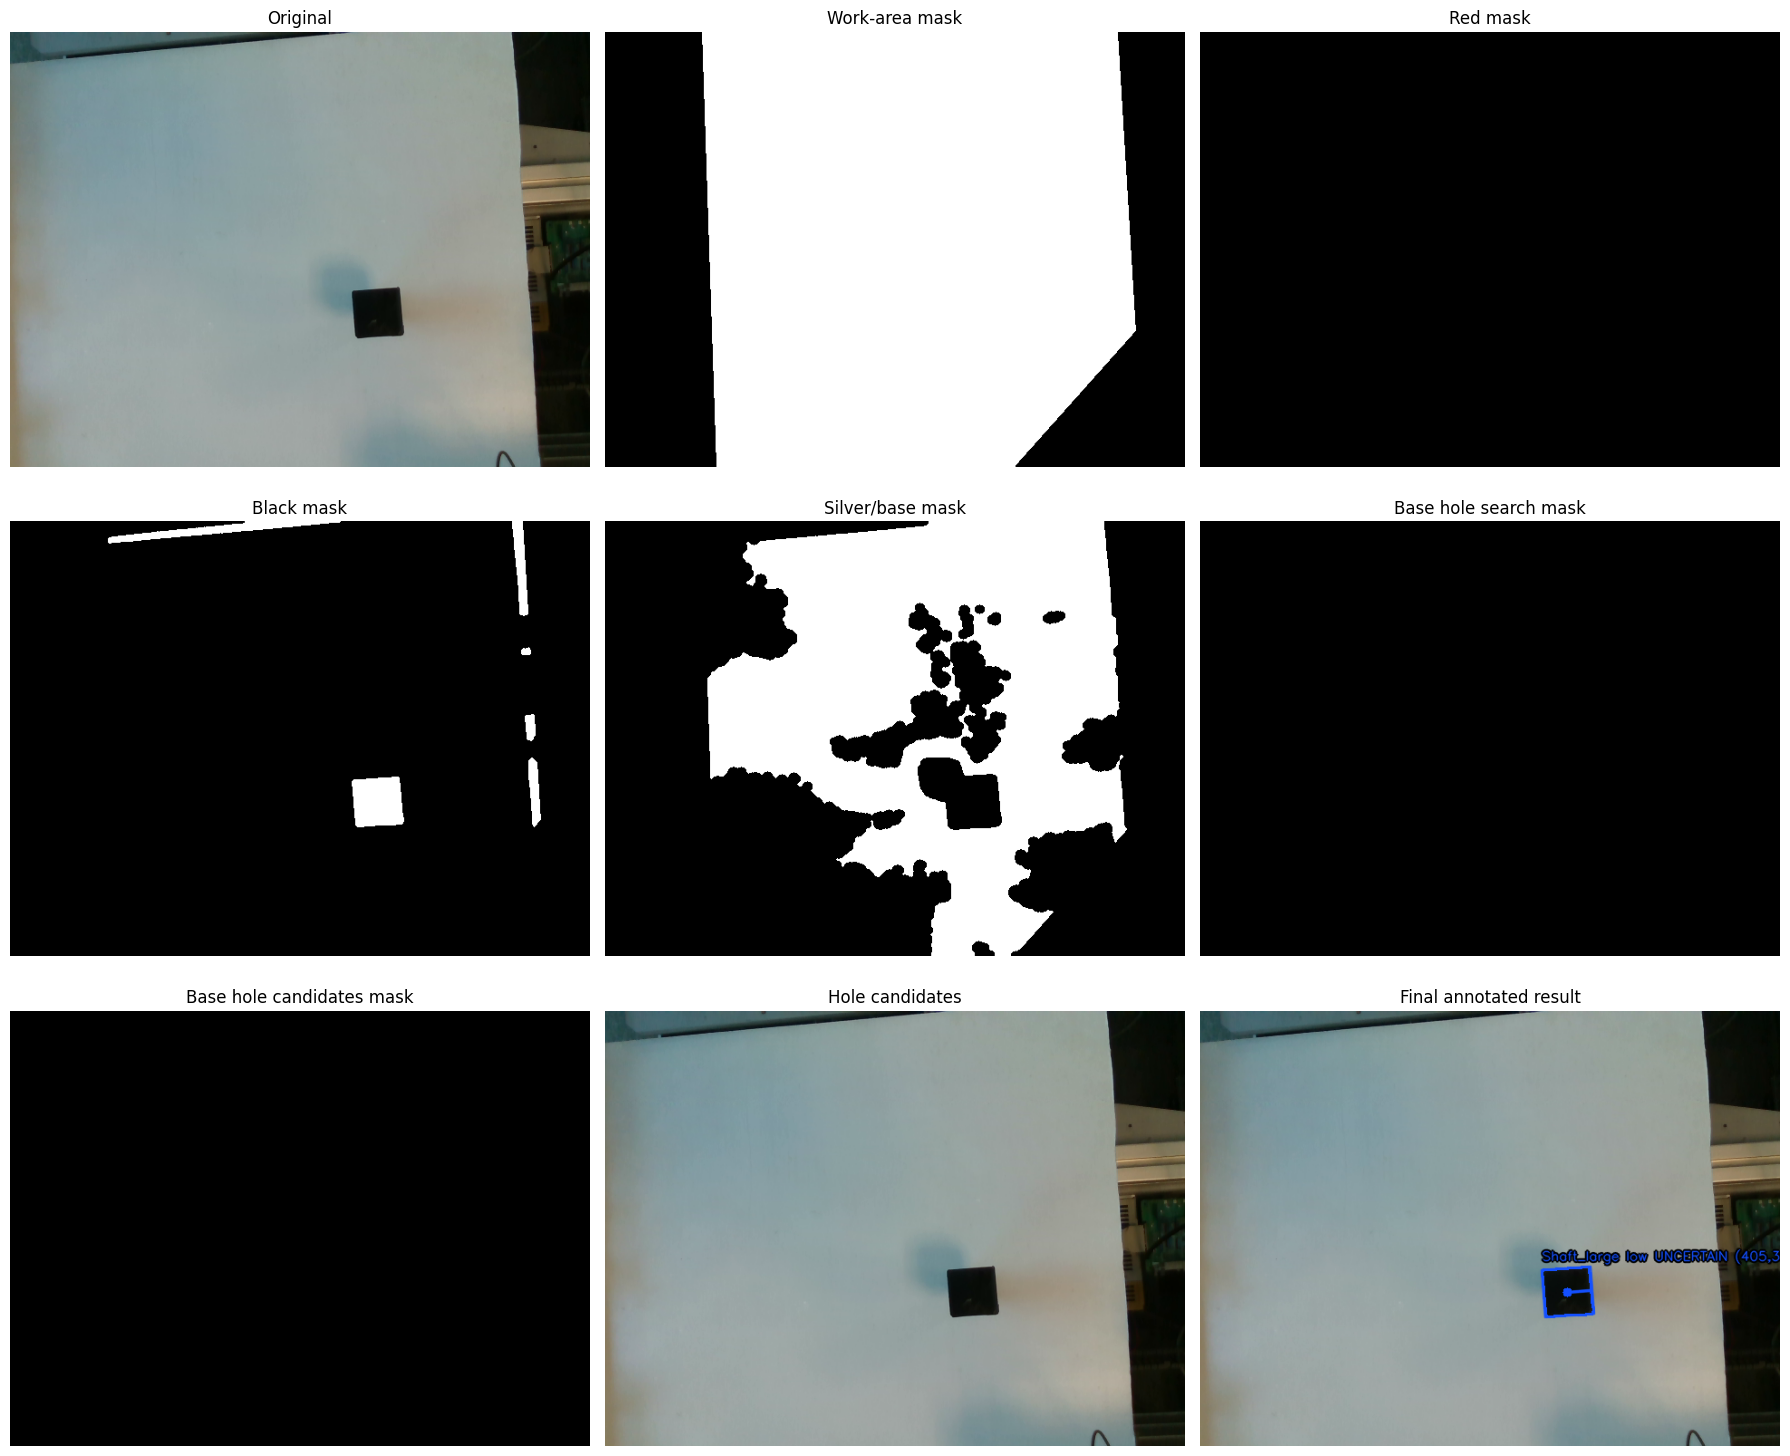


Detection summary:
  Shaft_large    center=(405.3, 309.6) confidence=low type_certain=False

NEW annotated image: /home/masais/Xinyu/output/global_detection/global_detection_result_black_holes.png
NEW debug image:     /home/masais/Xinyu/output/global_detection/global_detection_debug_black_holes.png
Saved CSV:           /home/masais/Xinyu/output/global_detection/global_detection_results.csv
Saved JSON:          /home/masais/Xinyu/output/global_detection/global_detection_results.json


In [38]:
print("Detector version: black-top-screw and perspective-hole v4")
DETECTION_RESULTS, DEBUG_IMAGES = main()

## Result summary

In [39]:
summary_fields = [
    "class_name", "center_u", "center_v", "bbox_x", "bbox_y",
    "bbox_w", "bbox_h", "area_px", "yaw_deg", "confidence", "rule_note",
    "type_certain", "classification_status", "classification_reason",
]
[
    {key: result.get(key) for key in summary_fields}
    for result in DETECTION_RESULTS
]

[{'class_name': 'Shaft_large',
  'center_u': 405.29,
  'center_v': 309.6,
  'bbox_x': 377,
  'bbox_y': 282,
  'bbox_w': 58,
  'bbox_h': 56,
  'area_px': 2713.0,
  'yaw_deg': -4.24,
  'confidence': 'low',
  'rule_note': 'only one shaft candidate detected; large label is provisional',
  'type_certain': False,
  'classification_status': 'uncertain',
  'classification_reason': 'shaft set incomplete or large/small rotated-area separation below 8%'}]

In [40]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from global_table_intersection_utils import (
    add_camera_table_intersection_to_detections,
    load_hand_eye_npz,
    pixel_to_table_intersection_camera,
)

HAND_EYE_NPZ_PATH = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.npz")
TABLE_Z_M = 0.0
CAMERA_FRAME_ID = "camera_color_optical_frame"
DEFAULT_CSV_PATH = Path("output/global_detection/global_detection_results.csv")
DEFAULT_JSON_PATH = Path("output/global_detection/global_detection_results.json")

csv_output_path = Path(globals().get("CSV_PATH", DEFAULT_CSV_PATH))
json_output_path = Path(globals().get("JSON_PATH", DEFAULT_JSON_PATH))

if "DETECTION_RESULTS" in globals():
    detection_results_source = globals().get("DETECTION_RESULTS_SOURCE", "in-memory DETECTION_RESULTS")
    detection_results_input = DETECTION_RESULTS
elif json_output_path.exists():
    detection_results_source = str(json_output_path)
    detection_results_input = json.loads(json_output_path.read_text(encoding="utf-8"))
else:
    raise FileNotFoundError(
        "没有找到可用的检测结果。请先运行 Run detection cell，或确认已有 global_detection_results.json。"
    )




def _json_safe(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, dict):
        return {
            str(key): _json_safe(val)
            for key, val in value.items()
            if not str(key).startswith("_")
        }
    if isinstance(value, (list, tuple)):
        return [_json_safe(item) for item in value]
    return value


def _public_augmented_result(item):
    return {
        str(key): _json_safe(value)
        for key, value in item.items()
        if not str(key).startswith("_")
    }

def _save_augmented_results(results, csv_path, json_path):
    csv_path = Path(csv_path)
    json_path = Path(json_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    json_path.parent.mkdir(parents=True, exist_ok=True)

    safe_results = [_public_augmented_result(item) for item in results]
    csv_rows = []
    for item in safe_results:
        row = {}
        for key, value in item.items():
            if isinstance(value, (list, dict)):
                row[key] = json.dumps(value, ensure_ascii=False)
            else:
                row[key] = value
        csv_rows.append(row)

    pd.DataFrame(csv_rows).to_csv(csv_path, index=False, encoding="utf-8-sig")
    json_path.write_text(
        json.dumps(safe_results, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


def _global_camera_coordinate_rows(results):
    rows = []
    for idx, item in enumerate(results):
        point_name = item.get("hole_name") or item.get("instance_name") or item.get("class_name") or f"point_{idx}"
        role = "base_hole" if item.get("hole_name") else "part_center"
        rows.append({
            "point_name": point_name,
            "role": role,
            "class_name": item.get("class_name"),
            "u_px": item.get("center_u"),
            "v_px": item.get("center_v"),
            "depth_valid": item.get("depth_valid"),
            "depth_m": item.get("depth_m"),
            "camera_x_m": item.get("camera_x_m"),
            "camera_y_m": item.get("camera_y_m"),
            "camera_z_m": item.get("camera_z_m"),
            "camera_frame_id": item.get("camera_frame_id"),
            "source": item.get("depth_source") or item.get("used_depth_source"),
            "reason": item.get("ray_table_intersection_reason"),
        })
    return rows

# Camera-frame table-intersection still needs the current robot pose because
# the table plane is defined in robot base frame as base_z = TABLE_Z_M.
# This identity pose is only for code/display testing. Replace it with the real
# Franka T_base_gripper for geometrically meaningful numbers.
T_base_gripper_global_observation = np.eye(4, dtype=np.float64)

T_gripper_camera_npz, CAMERA_MATRIX_NPZ, DIST_COEFFS_NPZ = load_hand_eye_npz(
    HAND_EYE_NPZ_PATH
)

example_intersection = pixel_to_table_intersection_camera(
    u=320.0,
    v=240.0,
    K=CAMERA_MATRIX_NPZ,
    T_base_gripper=T_base_gripper_global_observation,
    T_gripper_camera=T_gripper_camera_npz,
    z_table=TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)
print("Detection results source:", detection_results_source)
print("Camera-frame table-intersection example using placeholder T_base_gripper:")
for key in (
    "center_px",
    "camera_x_m",
    "camera_y_m",
    "camera_z_m",
    "camera_frame_id",
    "depth_valid",
    "ray_table_intersection_reason",
):
    print(f"  {key}: {example_intersection[key]}")

DETECTION_RESULTS_CAMERA_TABLE_OFFLINE = add_camera_table_intersection_to_detections(
    detection_results_input,
    CAMERA_MATRIX_NPZ,
    T_base_gripper_global_observation,
    T_gripper_camera_npz,
    TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)

_save_augmented_results(
    DETECTION_RESULTS_CAMERA_TABLE_OFFLINE,
    csv_output_path,
    json_output_path,
)

print("\nGlobal detection camera-frame coordinates")
print("Source:", detection_results_source)
print("Frame:", CAMERA_FRAME_ID)
print("Note: these are RGB ray/table-intersection coordinates, not raw-depth object surface coordinates.")
global_camera_df = pd.DataFrame(_global_camera_coordinate_rows(DETECTION_RESULTS_CAMERA_TABLE_OFFLINE))
display(global_camera_df)
shaft_large_rows = global_camera_df[
    global_camera_df["point_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
    | global_camera_df["class_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
]
if not shaft_large_rows.empty:
    print("\nshaft_large camera-frame coordinate row:")
    display(shaft_large_rows)
print("Saved augmented CSV:", csv_output_path)
print("Saved augmented JSON:", json_output_path)


Detection results source: final RealSense live frame
Camera-frame table-intersection example using placeholder T_base_gripper:
  center_px: [320.0, 240.0]
  camera_x_m: None
  camera_y_m: None
  camera_z_m: None
  camera_frame_id: camera_color_optical_frame
  depth_valid: False
  ray_table_intersection_reason: table intersection lies behind the camera

Global detection camera-frame coordinates
Source: final RealSense live frame
Frame: camera_color_optical_frame
Note: these are RGB ray/table-intersection coordinates, not raw-depth object surface coordinates.


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Shaft_large,part_center,Shaft_large,405.29,309.6,False,None,None,None,None,camera_color_optical_frame,rgb_ray_table_intersection,table intersection lies behind the camera



shaft_large camera-frame coordinate row:


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Shaft_large,part_center,Shaft_large,405.29,309.6,False,None,None,None,None,camera_color_optical_frame,rgb_ray_table_intersection,table intersection lies behind the camera


Saved augmented CSV: /home/masais/Xinyu/output/global_detection/global_detection_results.csv
Saved augmented JSON: /home/masais/Xinyu/output/global_detection/global_detection_results.json


In [41]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from global_table_intersection_utils import add_camera_table_intersection_to_detections, load_hand_eye_npz

HAND_EYE_NPZ_PATH = Path("cam_calibration/outputs/03_hand_eye/hand_eye_result.npz")
TABLE_Z_M = 0.0
CAMERA_FRAME_ID = "camera_color_optical_frame"
DEFAULT_CSV_PATH = Path("output/global_detection/global_detection_results.csv")
DEFAULT_JSON_PATH = Path("output/global_detection/global_detection_results.json")

csv_output_path = Path(globals().get("CSV_PATH", DEFAULT_CSV_PATH))
json_output_path = Path(globals().get("JSON_PATH", DEFAULT_JSON_PATH))

if "DETECTION_RESULTS" in globals():
    detection_results_source = globals().get("DETECTION_RESULTS_SOURCE", "in-memory DETECTION_RESULTS")
    detection_results_input = DETECTION_RESULTS
elif json_output_path.exists():
    detection_results_source = str(json_output_path)
    detection_results_input = json.loads(json_output_path.read_text(encoding="utf-8"))
else:
    raise FileNotFoundError(
        "没有找到可用的检测结果。请先运行 Run detection cell，或确认已有 global_detection_results.json。"
    )




def _json_safe(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, dict):
        return {
            str(key): _json_safe(val)
            for key, val in value.items()
            if not str(key).startswith("_")
        }
    if isinstance(value, (list, tuple)):
        return [_json_safe(item) for item in value]
    return value


def _public_augmented_result(item):
    return {
        str(key): _json_safe(value)
        for key, value in item.items()
        if not str(key).startswith("_")
    }

def _save_augmented_results(results, csv_path, json_path):
    csv_path = Path(csv_path)
    json_path = Path(json_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    json_path.parent.mkdir(parents=True, exist_ok=True)

    safe_results = [_public_augmented_result(item) for item in results]
    csv_rows = []
    for item in safe_results:
        row = {}
        for key, value in item.items():
            if isinstance(value, (list, dict)):
                row[key] = json.dumps(value, ensure_ascii=False)
            else:
                row[key] = value
        csv_rows.append(row)

    pd.DataFrame(csv_rows).to_csv(csv_path, index=False, encoding="utf-8-sig")
    json_path.write_text(
        json.dumps(safe_results, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


def _global_camera_coordinate_rows(results):
    rows = []
    for idx, item in enumerate(results):
        point_name = item.get("hole_name") or item.get("instance_name") or item.get("class_name") or f"point_{idx}"
        role = "base_hole" if item.get("hole_name") else "part_center"
        rows.append({
            "point_name": point_name,
            "role": role,
            "class_name": item.get("class_name"),
            "u_px": item.get("center_u"),
            "v_px": item.get("center_v"),
            "depth_valid": item.get("depth_valid"),
            "depth_m": item.get("depth_m"),
            "camera_x_m": item.get("camera_x_m"),
            "camera_y_m": item.get("camera_y_m"),
            "camera_z_m": item.get("camera_z_m"),
            "camera_frame_id": item.get("camera_frame_id"),
            "source": item.get("depth_source") or item.get("used_depth_source"),
            "reason": item.get("ray_table_intersection_reason"),
        })
    return rows

T_gripper_camera_npz, CAMERA_MATRIX_NPZ, DIST_COEFFS_NPZ = load_hand_eye_npz(
    HAND_EYE_NPZ_PATH
)

# Paste the real Franka current T_base_gripper here for the same global observation frame.
# Even though the output below is camera-frame only, this pose is still required because
# the table plane is defined in robot base frame as base_z = TABLE_Z_M.
T_base_gripper_manual = np.array([
    [0.994484450, -0.104394350, -0.010124177, 0.430363940],
    [-0.104163017, -0.994334701, 0.021179428, 0.042528753],
    [-0.012277833, -0.020008047, -0.999724428, 0.489648672],
    [0.000000000, 0.000000000, 0.000000000, 1.000000000],
], dtype=np.float64)

DETECTION_RESULTS_CAMERA_TABLE_MANUAL = add_camera_table_intersection_to_detections(
    detection_results_input,
    CAMERA_MATRIX_NPZ,
    T_base_gripper_manual,
    T_gripper_camera_npz,
    TABLE_Z_M,
    camera_frame_id=CAMERA_FRAME_ID,
)

_save_augmented_results(
    DETECTION_RESULTS_CAMERA_TABLE_MANUAL,
    csv_output_path,
    json_output_path,
)

print("Detection results source:", detection_results_source)
print("Frame:", CAMERA_FRAME_ID)
print("Note: replace T_base_gripper_manual with the real Franka pose before trusting these coordinates.")
global_camera_df = pd.DataFrame(_global_camera_coordinate_rows(DETECTION_RESULTS_CAMERA_TABLE_MANUAL))
display(global_camera_df)
shaft_large_rows = global_camera_df[
    global_camera_df["point_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
    | global_camera_df["class_name"].astype(str).str.lower().str.contains("shaft_large", na=False)
]
if not shaft_large_rows.empty:
    print("\nshaft_large camera-frame coordinate row:")
    display(shaft_large_rows)
print("Saved augmented CSV:", csv_output_path)
print("Saved augmented JSON:", json_output_path)


Detection results source: final RealSense live frame
Frame: camera_color_optical_frame
Note: replace T_base_gripper_manual with the real Franka pose before trusting these coordinates.


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Shaft_large,part_center,Shaft_large,405.29,309.6,True,0.430687,0.061992,0.038651,0.430687,camera_color_optical_frame,rgb_ray_table_intersection,None



shaft_large camera-frame coordinate row:


,point_name,role,class_name,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,camera_frame_id,source,reason
0,Shaft_large,part_center,Shaft_large,405.29,309.6,True,0.430687,0.061992,0.038651,0.430687,camera_color_optical_frame,rgb_ray_table_intersection,None


Saved augmented CSV: /home/masais/Xinyu/output/global_detection/global_detection_results.csv
Saved augmented JSON: /home/masais/Xinyu/output/global_detection/global_detection_results.json


In [42]:
# RealSense D435i live RGB global-detection viewer.
# Run this cell after all detection-function cells above have been executed.

import time
import numpy as np
import cv2


def detect_live_frame_bgr(color_bgr):
    """Run the existing notebook detection pipeline without saving anything."""
    work_mask = create_work_area_mask(color_bgr)
    red_mask = segment_red_objects(color_bgr, work_mask)
    black_mask = segment_black_objects(color_bgr, work_mask)
    base_mask = segment_silver_base(
        color_bgr, work_mask, red_mask, black_mask
    )

    red_results = detect_red_parts(color_bgr, red_mask)
    base_results = detect_silver_base(color_bgr, base_mask)
    # Base holes and their shadows also appear in the global black mask.
    # Remove the full detected base ROI only for shaft classification; hole
    # detection below still receives the unmodified black_mask.
    shaft_black_mask = black_mask.copy()
    if base_results:
        base_exclusion_mask = np.zeros_like(black_mask)
        cv2.drawContours(
            base_exclusion_mask, [base_results[0]["_contour"]],
            -1, 255, thickness=-1,
        )
        base_exclusion_mask = cv2.dilate(base_exclusion_mask, _odd_kernel(3))
        shaft_black_mask[base_exclusion_mask > 0] = 0
    shaft_results = detect_black_shafts(color_bgr, shaft_black_mask)

    hole_results = []
    hole_search_mask = np.zeros(color_bgr.shape[:2], dtype=np.uint8)
    hole_candidates_mask = np.zeros(color_bgr.shape[:2], dtype=np.uint8)
    hole_candidate_debug = color_bgr.copy()
    if base_results:
        (
            hole_results,
            hole_search_mask,
            hole_candidates_mask,
            hole_candidate_debug,
        ) = detect_base_insert_holes_from_black_mask(
            color_bgr, base_results[0]["_contour"], black_mask
        )

    results = red_results + shaft_results + base_results + hole_results
    annotated = draw_results(color_bgr, results)
    debug_views = {
        "annotated": annotated,
        "red_mask": red_mask,
        "black_mask": black_mask,
        "shaft_black_mask": shaft_black_mask,
        "base_mask": base_mask,
        "base_hole_search_mask": hole_search_mask,
        "base_hole_candidates_mask": hole_candidates_mask,
        "hole_candidate_debug": hole_candidate_debug,
    }
    return annotated, results, debug_views


def run_realsense_global_detection_live():
    """Open RealSense live view and keep the last frame as DETECTION_RESULTS.

    After quitting with q/ESC, downstream cells use the final live frame instead
    of the offline IMAGE_PATH result.
    """
    try:
        import pyrealsense2 as rs
    except ImportError:
        print(
            "pyrealsense2 is not installed. Install the RealSense Python "
            "package before running this cell."
        )
        return

    window_name = "RealSense Global Detection Live"
    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(
        rs.stream.color, 640, 480, rs.format.bgr8, 30
    )

    pipeline_started = False
    previous_gray = None
    stable_frame_count = 0
    paused = False
    display_mode_index = 0
    last_display = None
    last_results = []
    last_color_bgr = None
    last_annotated = None
    last_debug_views = None
    last_motion_score = 0.0
    last_state = "MOVING"
    fps = 0.0
    previous_time = None
    last_frame_timestamp_sec = None

    previous_results_source = globals().get("DETECTION_RESULTS_SOURCE")
    globals()["DETECTION_RESULTS_SOURCE"] = "RealSense live viewer started; no live frame processed yet"

    try:
        try:
            pipeline.start(config)
            pipeline_started = True
        except Exception as exc:
            print(
                "Could not start RealSense D435i. Check that the camera is "
                f"connected and not used by another process. Details: {exc}"
            )
            return

        print(
            "Live controls: q/ESC quit, space pause/resume, "
            "d cycle debug views."
        )
        try:
            cv2.startWindowThread()
        except Exception:
            pass
        try:
            cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
        except Exception as exc:
            print(
                "Could not create OpenCV display window. If you are running over SSH "
                "or inside a headless VSCode/Jupyter session, run the notebook on the "
                f"machine display or enable X forwarding. Details: {exc}"
            )
            return

        while True:
            if not paused:
                frames = pipeline.wait_for_frames(timeout_ms=5000)
                color_frame = frames.get_color_frame()
                if not color_frame:
                    print("No RealSense color frame received; retrying.")
                    continue

                color_bgr = np.asanyarray(color_frame.get_data())
                if color_bgr is None or color_bgr.size == 0:
                    print("Received an empty RealSense color frame; retrying.")
                    continue
                annotated, results, debug_views = detect_live_frame_bgr(
                    color_bgr
                )

                gray = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2GRAY)
                if previous_gray is None:
                    motion_score = 0.0
                    stable_frame_count = 0
                else:
                    motion_score = float(
                        cv2.mean(cv2.absdiff(gray, previous_gray))[0]
                    )
                    stable_frame_count = (
                        stable_frame_count + 1
                        if motion_score < 2.0
                        else 0
                    )
                previous_gray = gray
                state = "STABLE" if stable_frame_count >= 10 else "MOVING"

                now = time.perf_counter()
                if previous_time is not None:
                    instant_fps = 1.0 / max(now - previous_time, 1e-6)
                    fps = (
                        instant_fps
                        if fps <= 0.0
                        else 0.85 * fps + 0.15 * instant_fps
                    )
                previous_time = now

                available_modes = [
                    name
                    for name in (
                        "annotated",
                        "red_mask",
                        "black_mask",
                        "shaft_black_mask",
                        "base_mask",
                        "base_hole_search_mask",
                        "base_hole_candidates_mask",
                        "hole_candidate_debug",
                    )
                    if name in debug_views
                    and debug_views[name] is not None
                    and np.asarray(debug_views[name]).size > 0
                ]
                if not available_modes:
                    available_modes = ["annotated"]
                    debug_views["annotated"] = annotated
                display_mode_index %= len(available_modes)
                mode_name = available_modes[display_mode_index]
                view = debug_views[mode_name]
                if view.ndim == 2:
                    view = cv2.cvtColor(view, cv2.COLOR_GRAY2BGR)
                else:
                    view = view.copy()

                status_color = (
                    (40, 220, 40) if state == "STABLE" else (0, 165, 255)
                )
                cv2.putText(
                    view,
                    (
                        f"FPS {fps:5.1f}  num_results {len(results)}  "
                        f"{state}  motion_score {motion_score:.2f}"
                    ),
                    (10, 24),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    (0, 0, 0),
                    3,
                    cv2.LINE_AA,
                )
                cv2.putText(
                    view,
                    (
                        f"FPS {fps:5.1f}  num_results {len(results)}  "
                        f"{state}  motion_score {motion_score:.2f}"
                    ),
                    (10, 24),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    status_color,
                    1,
                    cv2.LINE_AA,
                )
                cv2.putText(
                    view,
                    f"view: {mode_name}",
                    (10, 47),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 255, 255),
                    1,
                    cv2.LINE_AA,
                )
                last_display = view
                last_results = results
                last_color_bgr = color_bgr.copy()
                last_annotated = annotated.copy()
                last_debug_views = {
                    name: image.copy() if isinstance(image, np.ndarray) else image
                    for name, image in debug_views.items()
                }
                last_motion_score = motion_score
                last_state = state
                last_frame_timestamp_sec = time.time()

                # Make the current live frame the notebook-wide latest result.
                # Cells below that read DETECTION_RESULTS will now use this live
                # frame instead of the offline IMAGE_PATH result.
                globals()["DETECTION_RESULTS"] = results
                globals()["DEBUG_IMAGES"] = debug_views
                globals()["LAST_LIVE_DETECTION_RESULTS"] = results
                globals()["LAST_LIVE_COLOR_BGR"] = color_bgr.copy()
                globals()["LAST_LIVE_ANNOTATED"] = annotated.copy()
                globals()["LAST_LIVE_DEBUG_VIEWS"] = debug_views
                globals()["LAST_LIVE_TIMESTAMP_SEC"] = last_frame_timestamp_sec
                globals()["DETECTION_RESULTS_SOURCE"] = "last RealSense live frame"
            elif last_display is not None:
                view = last_display.copy()
                cv2.putText(
                    view,
                    "PAUSED",
                    (10, 72),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 0, 255),
                    2,
                    cv2.LINE_AA,
                )
                last_display = view

            if last_display is not None:
                cv2.imshow(window_name, last_display)

            key = cv2.waitKey(1 if not paused else 30) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord(" "):
                paused = not paused
                print("Live view paused." if paused else "Live view resumed.")
            elif key == ord("d"):
                display_mode_index += 1
                print("Debug view changed.")

    except KeyboardInterrupt:
        print("Live detection interrupted.")
    except Exception as exc:
        print(f"RealSense live detection stopped after an error: {exc}")
    finally:
        if pipeline_started:
            pipeline.stop()
        cv2.destroyAllWindows()
        if last_annotated is not None:
            # Commit exactly the final processed live frame. If the view was
            # paused before quitting, this is the frozen frame. IMAGE_PATH is
            # not read anywhere in this live path.
            globals()["DETECTION_RESULTS"] = last_results
            globals()["DEBUG_IMAGES"] = last_debug_views
            globals()["LAST_LIVE_DETECTION_RESULTS"] = last_results
            globals()["LAST_LIVE_COLOR_BGR"] = last_color_bgr
            globals()["LAST_LIVE_ANNOTATED"] = last_annotated
            globals()["LAST_LIVE_DEBUG_VIEWS"] = last_debug_views
            globals()["LAST_LIVE_TIMESTAMP_SEC"] = last_frame_timestamp_sec
            globals()["LAST_LIVE_FRAME_AVAILABLE"] = True
            globals()["DETECTION_RESULTS_SOURCE"] = (
                "final paused RealSense live frame"
                if paused else "final RealSense live frame"
            )
            names = [
                item.get("hole_name") or item.get("instance_name") or item.get("class_name")
                for item in last_results
            ]
            print(
                "Final live frame stored in DETECTION_RESULTS: "
                f"{len(last_results)} detections -> {names}"
            )
        else:
            globals()["LAST_LIVE_FRAME_AVAILABLE"] = False
            if previous_results_source is not None:
                globals()["DETECTION_RESULTS_SOURCE"] = previous_results_source
            print("No RealSense live frame was processed; existing results were not overwritten.")
        print("RealSense live detection closed.")

    return last_results if last_annotated is not None else None


FINAL_LIVE_DETECTION_RESULTS = run_realsense_global_detection_live()
if FINAL_LIVE_DETECTION_RESULTS is not None:
    # Persist and display the same final live frame committed above.
    save_results_csv(FINAL_LIVE_DETECTION_RESULTS, CSV_PATH)
    save_results_json(FINAL_LIVE_DETECTION_RESULTS, JSON_PATH)
    if LAST_LIVE_ANNOTATED is not None:
        cv2.imwrite(str(ANNOTATED_PATH), LAST_LIVE_ANNOTATED)
    if LAST_LIVE_COLOR_BGR is not None:
        cv2.imwrite(
            str(OUTPUT_DIR / "global_detection_last_live_color.png"),
            LAST_LIVE_COLOR_BGR,
        )
    for debug_name, debug_image in (LAST_LIVE_DEBUG_VIEWS or {}).items():
        if isinstance(debug_image, np.ndarray) and debug_image.ndim in (2, 3):
            cv2.imwrite(
                str(OUTPUT_DIR / f"global_detection_last_live_{debug_name}.png"),
                debug_image,
            )
    FINAL_LIVE_RESULT_SUMMARY = [
        _public_result(item) for item in FINAL_LIVE_DETECTION_RESULTS
    ]
    print("Detection results source:", DETECTION_RESULTS_SOURCE)
    _print_detection_summary(FINAL_LIVE_DETECTION_RESULTS)
    print("Final live JSON:", JSON_PATH)
    print("Final live CSV:", CSV_PATH)
else:
    FINAL_LIVE_RESULT_SUMMARY = []

FINAL_LIVE_RESULT_SUMMARY


Live controls: q/ESC quit, space pause/resume, d cycle debug views.
Final live frame stored in DETECTION_RESULTS: 1 detections -> ['Shaft_large']
RealSense live detection closed.
Detection results source: final RealSense live frame

Detection summary:
  Shaft_large    center=(373.7, 195.4) confidence=low type_certain=False
Final live JSON: /home/masais/Xinyu/output/global_detection/global_detection_results.json
Final live CSV: /home/masais/Xinyu/output/global_detection/global_detection_results.csv


[{'class_name': 'Shaft_large',
  'center_u': 373.68,
  'center_v': 195.45,
  'bbox_x': 347,
  'bbox_y': 168,
  'bbox_w': 55,
  'bbox_h': 54,
  'area_px': 1571.0,
  'yaw_deg': -57.65,
  'confidence': 'low',
  'rule_note': 'only one shaft candidate detected; large label is provisional',
  'type_certain': False,
  'classification_status': 'uncertain',
  'classification_reason': 'shaft set incomplete or large/small rotated-area separation below 8%',
  'classification_set_complete': False,
  'shaft_size_margin_ratio': None,
  'gear_outer_radius_px': None,
  'gear_inner_square_center': None,
  'grasp_hint_2d': None,
  'rect_width_px': 43.59,
  'rect_height_px': 39.03,
  'long_side_px': 43.59,
  'short_side_px': 39.03,
  'edge_midpoints_2d': [[361.8778381347656, 214.4559783935547],
   [357.0531005859375, 185.60031127929688],
   [385.2021789550781, 177.62806701660156],
   [390.02691650390625, 206.48373413085938]],
  'grasp_candidates_2d': [[373.5400085449219, 196.04202270507812],
   [378.67136